# Decision Tree – Heart Disease Prediction

## 1. Project Introduction

### Business Context
Heart disease is one of the major health concerns worldwide. Early identification of heart disease risk can help healthcare professionals make better decisions and provide timely medical attention.

Machine Learning techniques can analyze patient medical information and identify patterns associated with heart disease.

### Project Objective
The objective of this project is to build a Decision Tree Classification model that predicts whether a patient has heart disease based on medical attributes.

### Problem Statement
This is a **Supervised Machine Learning – Binary Classification** problem.

- 0 – No Heart Disease
- 1 – Heart Disease

### Dataset Features
The dataset contains patient information such as age, sex, chest pain type, resting blood pressure, cholesterol, maximum heart rate, exercise-induced angina and other medical measurements.

## 2. Importing Libraries and Loading Dataset

In this section, we import the necessary Python libraries for data manipulation, visualization, preprocessing and machine learning.

We then load the heart disease dataset using Pandas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import (DecisionTreeClassifier,
                          plot_tree)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
    )

In [2]:
df=pd.read_csv("d:\\project\\11. Decision Tree\\heart_disease.csv")

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the structure, quality and characteristics of the dataset before building a Machine Learning model.

The following activities are performed:

- Display the first and last five records.
- Check the number of rows and columns.
- Understand column names and data types.
- Calculate descriptive statistics.
- Identify missing values.
- Identify completely empty rows.

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63.0,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,FALSE,2.3,downsloping,fixed defect,0.0
1,41.0,Male,atypical angina,135.0,203.0,False,normal,132.0,FALSE,0.0,flat,fixed defect,0.0
2,57.0,Male,asymptomatic,140.0,192.0,False,normal,148.0,FALSE,0.4,flat,fixed defect,0.0
3,52.0,Male,typical angina,118.0,186.0,False,lv hypertrophy,190.0,FALSE,0.0,flat,fixed defect,0.0
4,57.0,Male,asymptomatic,110.0,201.0,False,normal,126.0,TRUE,1.5,flat,fixed defect,0.0


In [4]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(("info"),df.info())
print(("describe"),df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    float64
 1   sex       908 non-null    str    
 2   cp        908 non-null    str    
 3   trestbps  908 non-null    float64
 4   chol      908 non-null    float64
 5   fbs       908 non-null    object 
 6   restecg   908 non-null    str    
 7   thalch    908 non-null    float64
 8   exang     908 non-null    str    
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    str    
 11  thal      908 non-null    str    
 12  num       908 non-null    float64
dtypes: float64(6), object(1), str(6)
memory usage: 146.1+ KB
info None
describe               age    trestbps        chol      thalch     oldpeak         num
count  908.000000  908.000000  908.000000  908.000000  846.000000  908.000000
mean    53.791850  133.430617  201.484581  135.957048    0.891253    1.008811
std   

In [6]:
print(("null values"),df.isnull().sum())
print(("shape"),df.shape)

null values age          91
sex          91
cp           91
trestbps     91
chol         91
fbs          91
restecg      91
thalch       91
exang        91
oldpeak     153
slope        91
thal         91
num          91
dtype: int64
shape (999, 13)


In [7]:
df[df.isnull().all(axis=1)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
909,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
911,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
912,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.dropna(how='all', inplace=True)

In [9]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
903,53.0,Male,asymptomatic,125.0,0.0,False,normal,120.0,FALSE,1.5,upsloping,reversable defect,4.0
904,62.0,Male,asymptomatic,166.0,170.0,False,st-t abnormality,120.0,TRUE,3.0,flat,fixed defect,4.0
905,56.0,Male,non-anginal,170.0,0.0,False,lv hypertrophy,123.0,TRUE,2.5,downsloping,fixed defect,4.0
906,56.0,Male,non-anginal,144.0,208.0,True,st-t abnormality,105.0,TURE,NaN,downsloping,reversable defect,4.0
907,57.0,Male,asymptomatic,142.0,277.0,True,st-t abnormality,182.0,FALSE,NaN,flat,reversable defect,4.0


In [10]:
df.shape

(908, 13)

In [11]:
df.isnull().sum()


age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

In [12]:
df['oldpeak'].isnull().sum()

np.int64(62)

## 4. Data Cleaning and Preprocessing

Data cleaning is performed to improve the quality and consistency of the dataset.

The following preprocessing steps are performed:

### 4.1 Removing Completely Empty Rows
Remove records where all columns contain missing values.

### 4.2 Handling Missing Values
Identify missing values and fill the missing values in the `oldpeak` column using the median.

### 4.3 Checking Categorical Variables
Identify unique categories and check their frequency and missing values.

### 4.4 Outlier Detection
Use boxplots and the Interquartile Range (IQR) method to identify potential outliers.

### 4.5 Outlier Treatment
Apply IQR-based capping to limit extreme values while retaining patient records.

In [13]:
print("Mean:", df['oldpeak'].mean())
print("Median:", df['oldpeak'].median())

Mean: 0.8912529550827422
Median: 0.5


In [14]:
df['oldpeak'] = df['oldpeak'].fillna(df['oldpeak'].median())

In [15]:
df['oldpeak'].isnull().sum()

np.int64(0)

In [16]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch',
       'exang', 'oldpeak', 'slope', 'thal', 'num'],
      dtype='str')

In [17]:
df['sex'].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [18]:
df['sex'].nunique()

2

In [19]:
df["sex"] = df["sex"].map({"Male": 1, "Female": 2})

In [20]:
df['cp'].unique()
df['fbs'].unique()
df['restecg'].unique()
df['exang'].unique()
df['slope'].unique()
df['thal'].unique()

<ArrowStringArray>
['fixed defect', 'normal', 'reversable defect']
Length: 3, dtype: str

## 5. Data Visualization and Feature Analysis

Data visualization helps us understand the distribution of individual features and relationships between variables.

### 5.1 Histograms
Histograms are used to understand the distribution of numerical variables and identify skewness and unusual patterns.

### 5.2 Count Plots
Count plots are used to understand the frequency distribution of categorical variables.

### 5.3 Correlation Heatmap
A correlation heatmap is used to identify positive and negative relationships between numerical features.

### 5.4 Feature Correlation with Target
Analyze the correlation between independent features and the target variable to understand their potential relationship with heart disease.

In [21]:
categorical_cols = ['sex', 'cp', 'fbs', 'restecg',
                    'exang', 'slope', 'thal']

for col in categorical_cols:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in sex:
[1 2]

Unique values in cp:
<ArrowStringArray>
['typical angina', 'atypical angina', 'asymptomatic', 'non-anginal']
Length: 4, dtype: str

Unique values in fbs:
[True False]

Unique values in restecg:
<ArrowStringArray>
['lv hypertrophy', 'normal', 'st-t abnormality']
Length: 3, dtype: str

Unique values in exang:
<ArrowStringArray>
['FALSE', 'TRUE', 'TURE']
Length: 3, dtype: str

Unique values in slope:
<ArrowStringArray>
['downsloping', 'flat', 'upsloping']
Length: 3, dtype: str

Unique values in thal:
<ArrowStringArray>
['fixed defect', 'normal', 'reversable defect']
Length: 3, dtype: str


In [22]:
df[categorical_cols].isnull().sum()

sex        0
cp         0
fbs        0
restecg    0
exang      0
slope      0
thal       0
dtype: int64

In [23]:
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

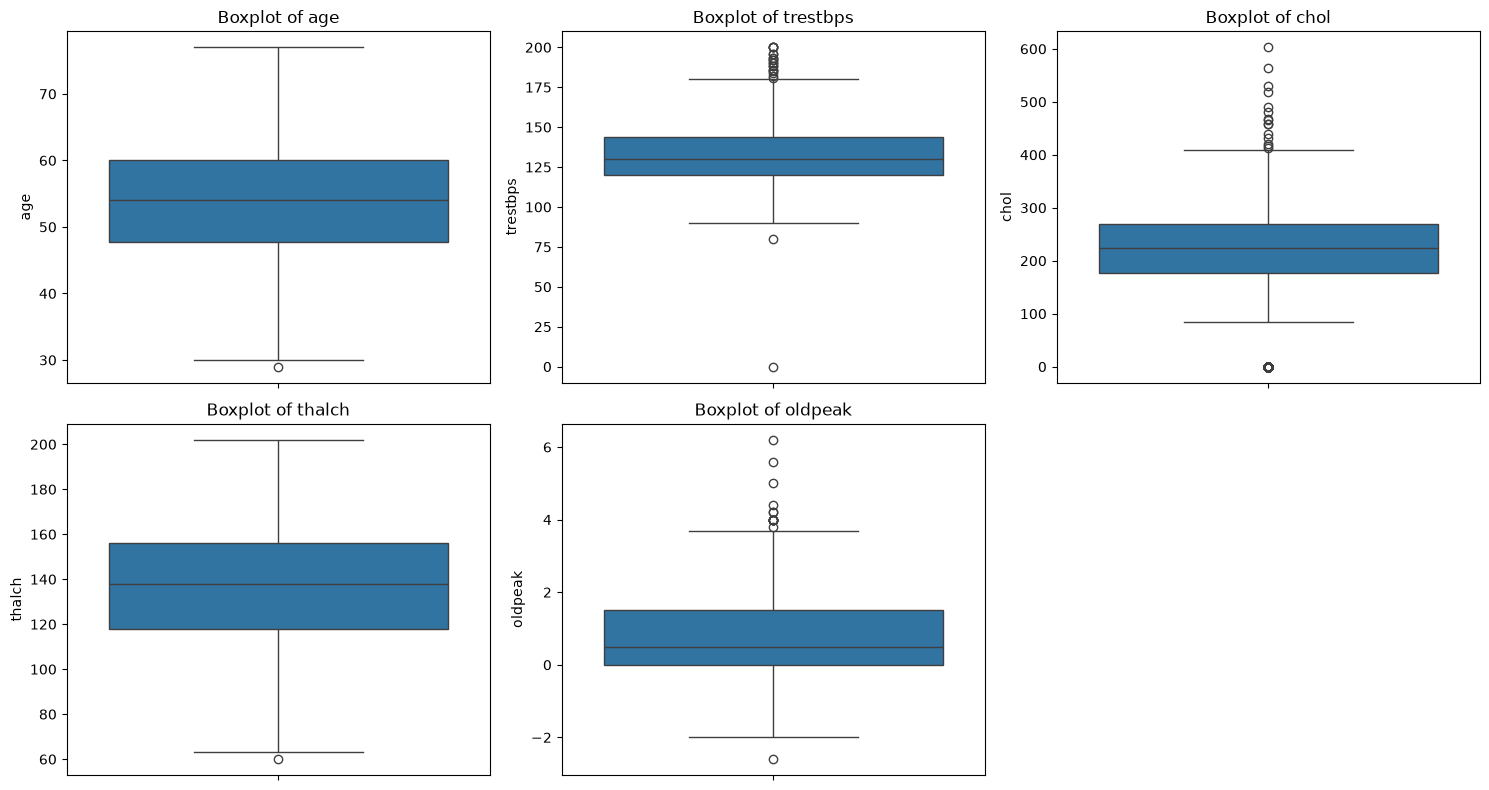

In [24]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [25]:
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))
    print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")


Column: age
Lower limit: 29.375
Upper limit: 78.375
Number of outliers: 1
Outlier percentage: 0.11 %

Column: trestbps
Lower limit: 84.0
Upper limit: 180.0
Number of outliers: 22
Outlier percentage: 2.42 %

Column: chol
Lower limit: 36.875
Upper limit: 409.875
Number of outliers: 187
Outlier percentage: 20.59 %

Column: thalch
Lower limit: 61.0
Upper limit: 213.0
Number of outliers: 1
Outlier percentage: 0.11 %

Column: oldpeak
Lower limit: -2.25
Upper limit: 3.75
Number of outliers: 16
Outlier percentage: 1.76 %


In [26]:
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col} outlier values:")
    print(outliers[col].sort_values().to_list())


age outlier values:
[29.0]

trestbps outlier values:
[0.0, 80.0, 181.0, 182.0, 184.0, 185.0, 186.0, 186.0, 188.0, 188.0, 190.0, 190.0, 192.0, 192.0, 193.0, 193.0, 196.0, 196.0, 200.0, 200.0, 200.0, 200.0]

chol outlier values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0

In [27]:
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)

In [28]:
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Remaining outliers:", len(outliers))

age Remaining outliers: 0
trestbps Remaining outliers: 0
chol Remaining outliers: 0
thalch Remaining outliers: 0
oldpeak Remaining outliers: 0


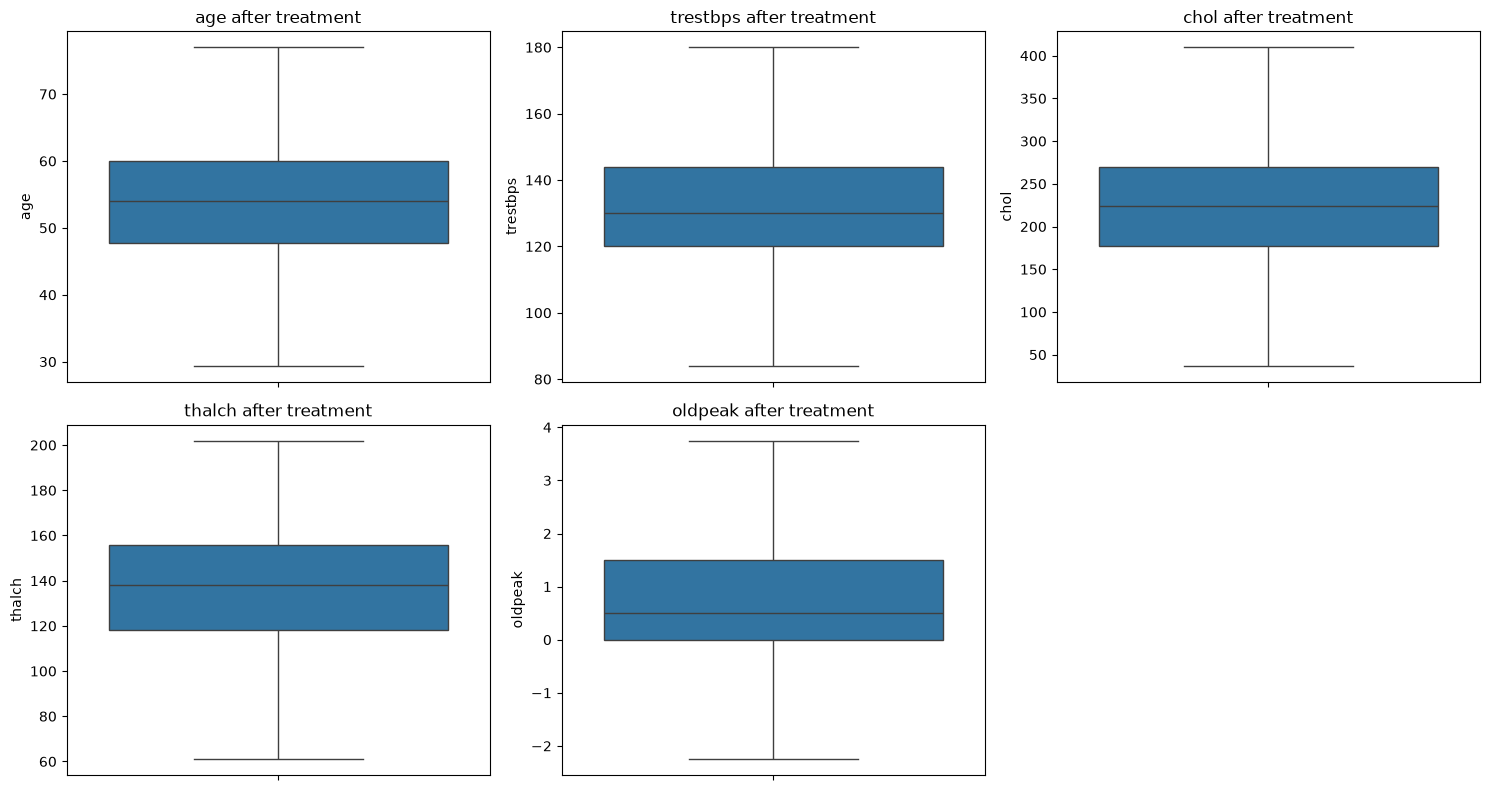

In [29]:

plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'{col} after treatment')

plt.tight_layout()
plt.show()

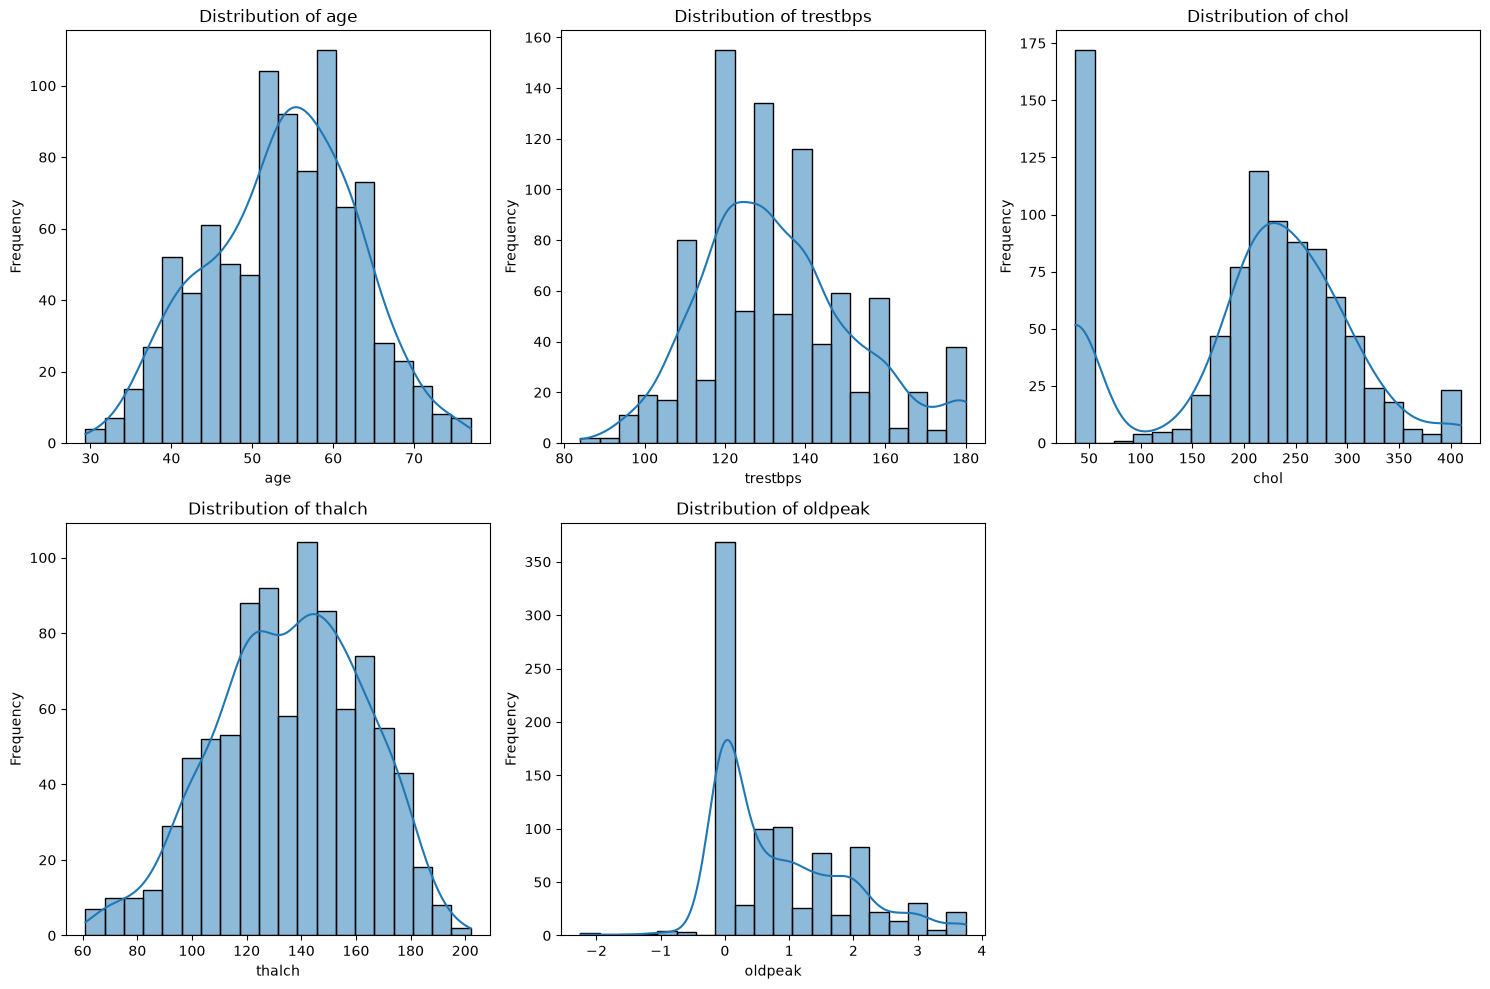

In [30]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

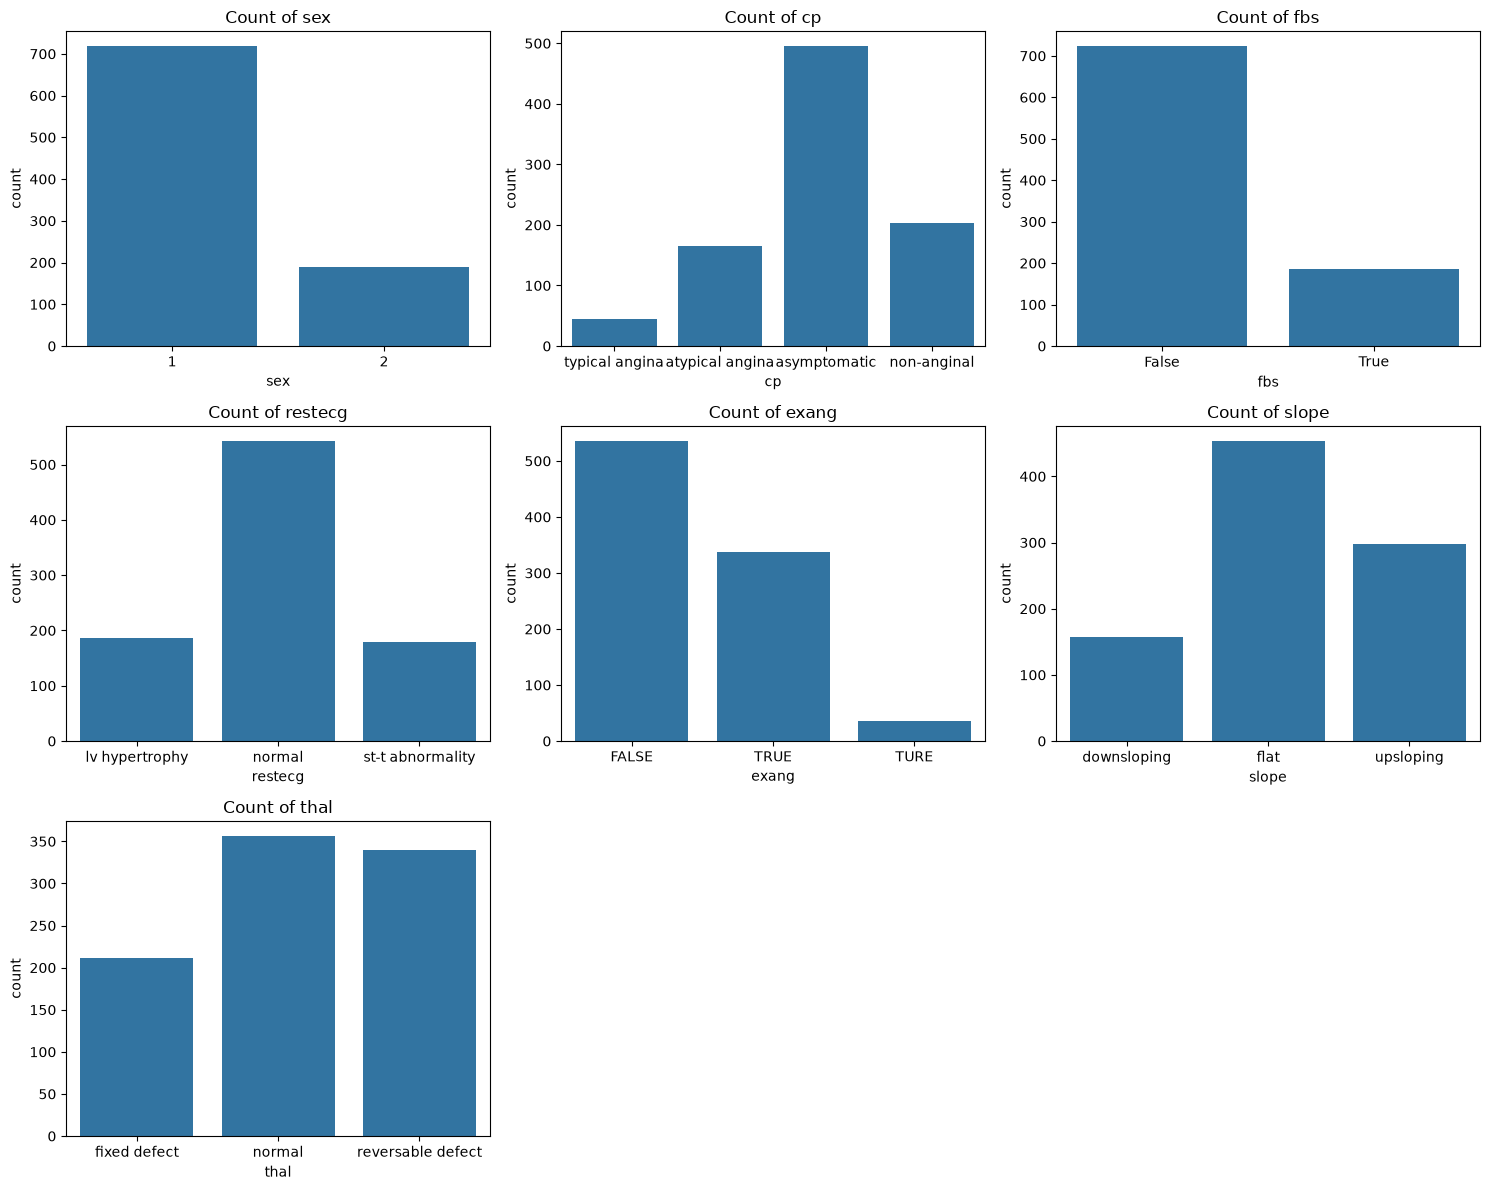

In [31]:
plt.figure(figsize=(15, 12))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')

plt.tight_layout()
plt.show()

In [32]:
correlation = df.corr(numeric_only=True)

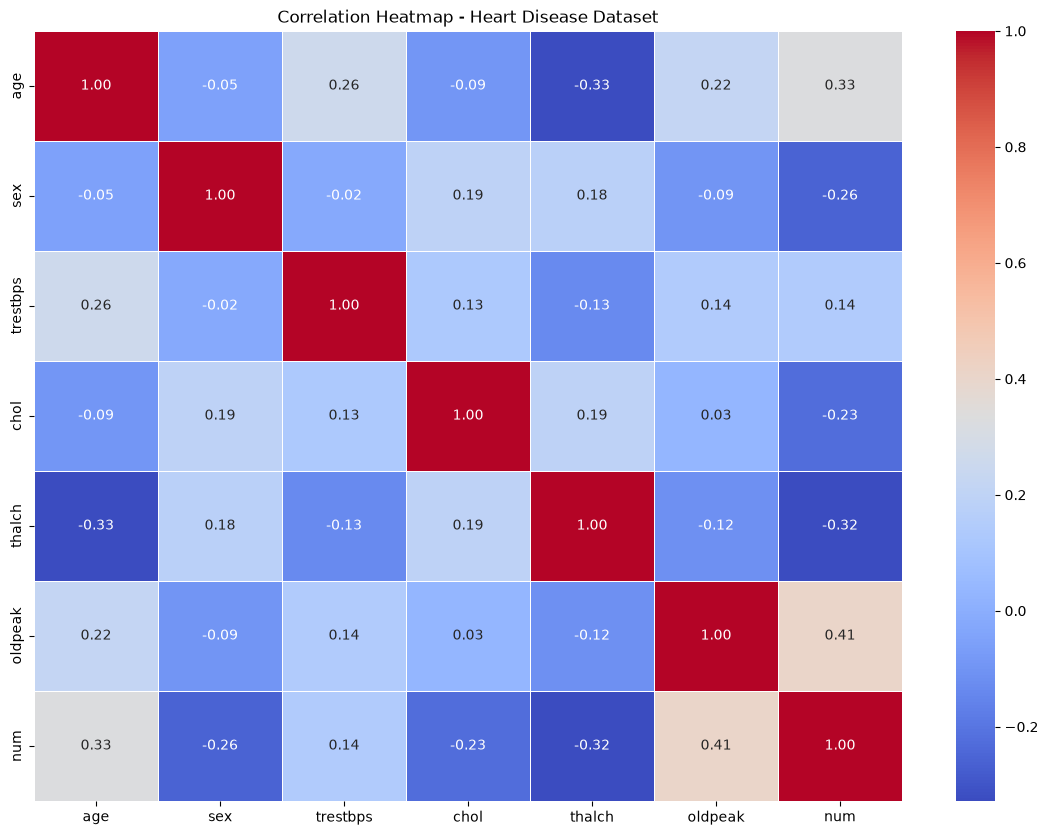

In [33]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap - Heart Disease Dataset')
plt.show()

In [34]:
target_corr = correlation['num'].sort_values(
    ascending=False
)

print(target_corr)

num         1.000000
oldpeak     0.406053
age         0.326493
trestbps    0.142645
chol       -0.228308
sex        -0.259605
thalch     -0.323060
Name: num, dtype: float64


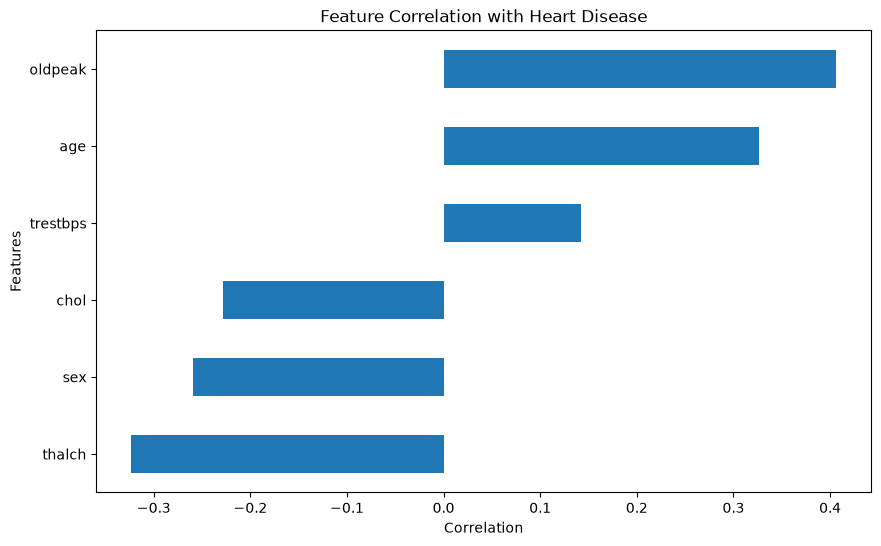

In [35]:
plt.figure(figsize=(10, 6))

target_corr.drop('num').sort_values().plot(
    kind='barh'
)

plt.title('Feature Correlation with Heart Disease')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.show()

## 6. Feature Selection and Target Encoding

### 6.1 Independent Variables (X)
Independent variables are the input features used by the Machine Learning model to make predictions.

### 6.2 Dependent Variable (y)
The dependent variable is the target that the model is expected to predict.

### 6.3 Target Encoding
The original target variable `num` contains multiple categories representing different levels of heart disease.

For binary classification, the target is converted into:

- 0 – No Heart Disease
- 1 – Heart Disease

All original values greater than zero are classified as heart disease.


## 7. Train-Test Split and Model Preparation

The dataset is divided into training and testing sets.

- Training data (80%): Used to train the Decision Tree model.
- Testing data (20%): Used to evaluate model performance on unseen records.

Categorical independent variables are converted into numerical representations using One-Hot Encoding.

Stratified splitting is used to maintain the proportion of both target classes in the training and testing datasets.

In [ ]:
# Convert target into binary classification
df['target'] = (df['num'] > 0).astype(int)

# Separate X and y
X = df.drop(columns=['num', 'target'])
y = df['target']

# Encode categorical features
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Split data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [39]:
y = (df['num'] > 0).astype(int)

In [40]:
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [41]:
X_train.select_dtypes(include=['object']).columns

C:\Users\saniy\AppData\Local\Temp\ipykernel_9084\1043803422.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train.select_dtypes(include=['object']).columns


Index(['cp', 'fbs', 'restecg', 'exang', 'slope', 'thal'], dtype='str')

In [42]:
for col in X_train.select_dtypes(include=['object']).columns:
    print(col, X_train[col].unique())

cp <ArrowStringArray>
['non-anginal', 'atypical angina', 'asymptomatic', 'typical angina']
Length: 4, dtype: str
fbs [False True]
restecg <ArrowStringArray>
['lv hypertrophy', 'normal', 'st-t abnormality']
Length: 3, dtype: str
exang <ArrowStringArray>
['FALSE', 'TRUE', 'TURE']
Length: 3, dtype: str
slope <ArrowStringArray>
['flat', 'downsloping', 'upsloping']
Length: 3, dtype: str
thal <ArrowStringArray>
['normal', 'reversable defect', 'fixed defect']
Length: 3, dtype: str


C:\Users\saniy\AppData\Local\Temp\ipykernel_9084\3364317938.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_train.select_dtypes(include=['object']).columns:


In [43]:
cat_cols = X_train.select_dtypes(include=['object']).columns

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols])

X_test[cat_cols] = encoder.transform(X_test[cat_cols])

C:\Users\saniy\AppData\Local\Temp\ipykernel_9084\2663172855.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=['object']).columns


In [44]:
print(X_train.select_dtypes(include=['object']).columns)

Index([], dtype='str')


## 8. Decision Tree Model Building

A Decision Tree Classifier is a supervised Machine Learning algorithm that makes predictions using a tree-like structure of decisions.

The model divides the dataset into smaller groups based on feature conditions until it reaches a final prediction.

The initial Decision Tree model is trained using the training dataset and used to predict heart disease on the testing dataset.

In [45]:

dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [46]:
y_pred = dt_model.predict(X_test)

In [47]:
print(y_test.unique())
print(y_pred)

[0. 2. 1. 4. 3.]
[0. 1. 0. 1. 1. 3. 1. 1. 1. 1. 0. 0. 2. 3. 1. 1. 0. 0. 1. 1. 1. 0. 1. 1.
 0. 0. 1. 1. 0. 0. 0. 1. 0. 1. 0. 1. 1. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 3. 1. 0. 1. 1. 1. 0. 3. 2. 0. 1. 2. 1. 3.
 1. 0. 2. 0. 1. 0. 1. 0. 0. 1. 1. 0. 0. 0. 0. 3. 3. 1. 0. 1. 1. 1. 1. 0.
 0. 1. 0. 2. 1. 0. 1. 2. 0. 0. 0. 2. 2. 0. 0. 0. 2. 0. 1. 3. 0. 1. 0. 0.
 1. 0. 0. 0. 1. 2. 0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 2. 1. 0. 3. 1. 2. 0. 3.
 3. 0. 1. 0. 1. 0. 1. 0. 1. 0. 0. 1. 3. 2. 0. 0. 1. 0. 3. 0. 0. 1. 3. 2.
 1. 1. 2. 2. 0. 1. 0. 0. 2. 0. 0. 0. 0. 0.]


## 9. Model Evaluation

The Decision Tree model is evaluated using different classification metrics.

### Evaluation Metrics

- Accuracy: Measures the overall percentage of correct predictions.
- Precision: Measures how many predicted positive cases are actually positive.
- Recall: Measures how many actual positive cases are correctly identified.
- F1 Score: Represents the balance between precision and recall.
- ROC-AUC: Measures the model's ability to distinguish between the two classes.

### Confusion Matrix
The confusion matrix helps identify correct and incorrect predictions made by the model.

In [48]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))

Accuracy: 0.5054945054945055
Precision: 0.4710705485775212
Recall: 0.5054945054945055
F1 Score: 0.48544848876493274


c:\Users\saniy\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [49]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

         0.0       0.71      0.78      0.74        80
         1.0       0.36      0.43      0.39        53
         2.0       0.24      0.18      0.21        22
         3.0       0.21      0.14      0.17        21
         4.0       0.00      0.00      0.00         6

    accuracy                           0.51       182
   macro avg       0.30      0.31      0.30       182
weighted avg       0.47      0.51      0.49       182



c:\Users\saniy\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\saniy\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\saniy\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

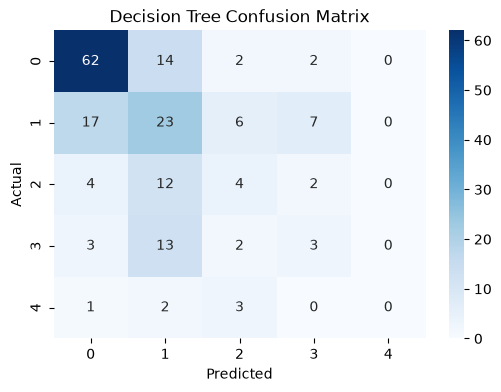

In [50]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')
plt.show()

In [51]:
print("Classes:", dt_model.classes_)
print("Number of classes:", len(dt_model.classes_))

Classes: [0. 1. 2. 3. 4.]
Number of classes: 5


## 10. Feature Importance and Tree Visualization

Feature importance helps identify which input variables contribute most to the Decision Tree's predictions.

The Decision Tree is also visualized to understand how the model makes decisions based on different patient attributes.

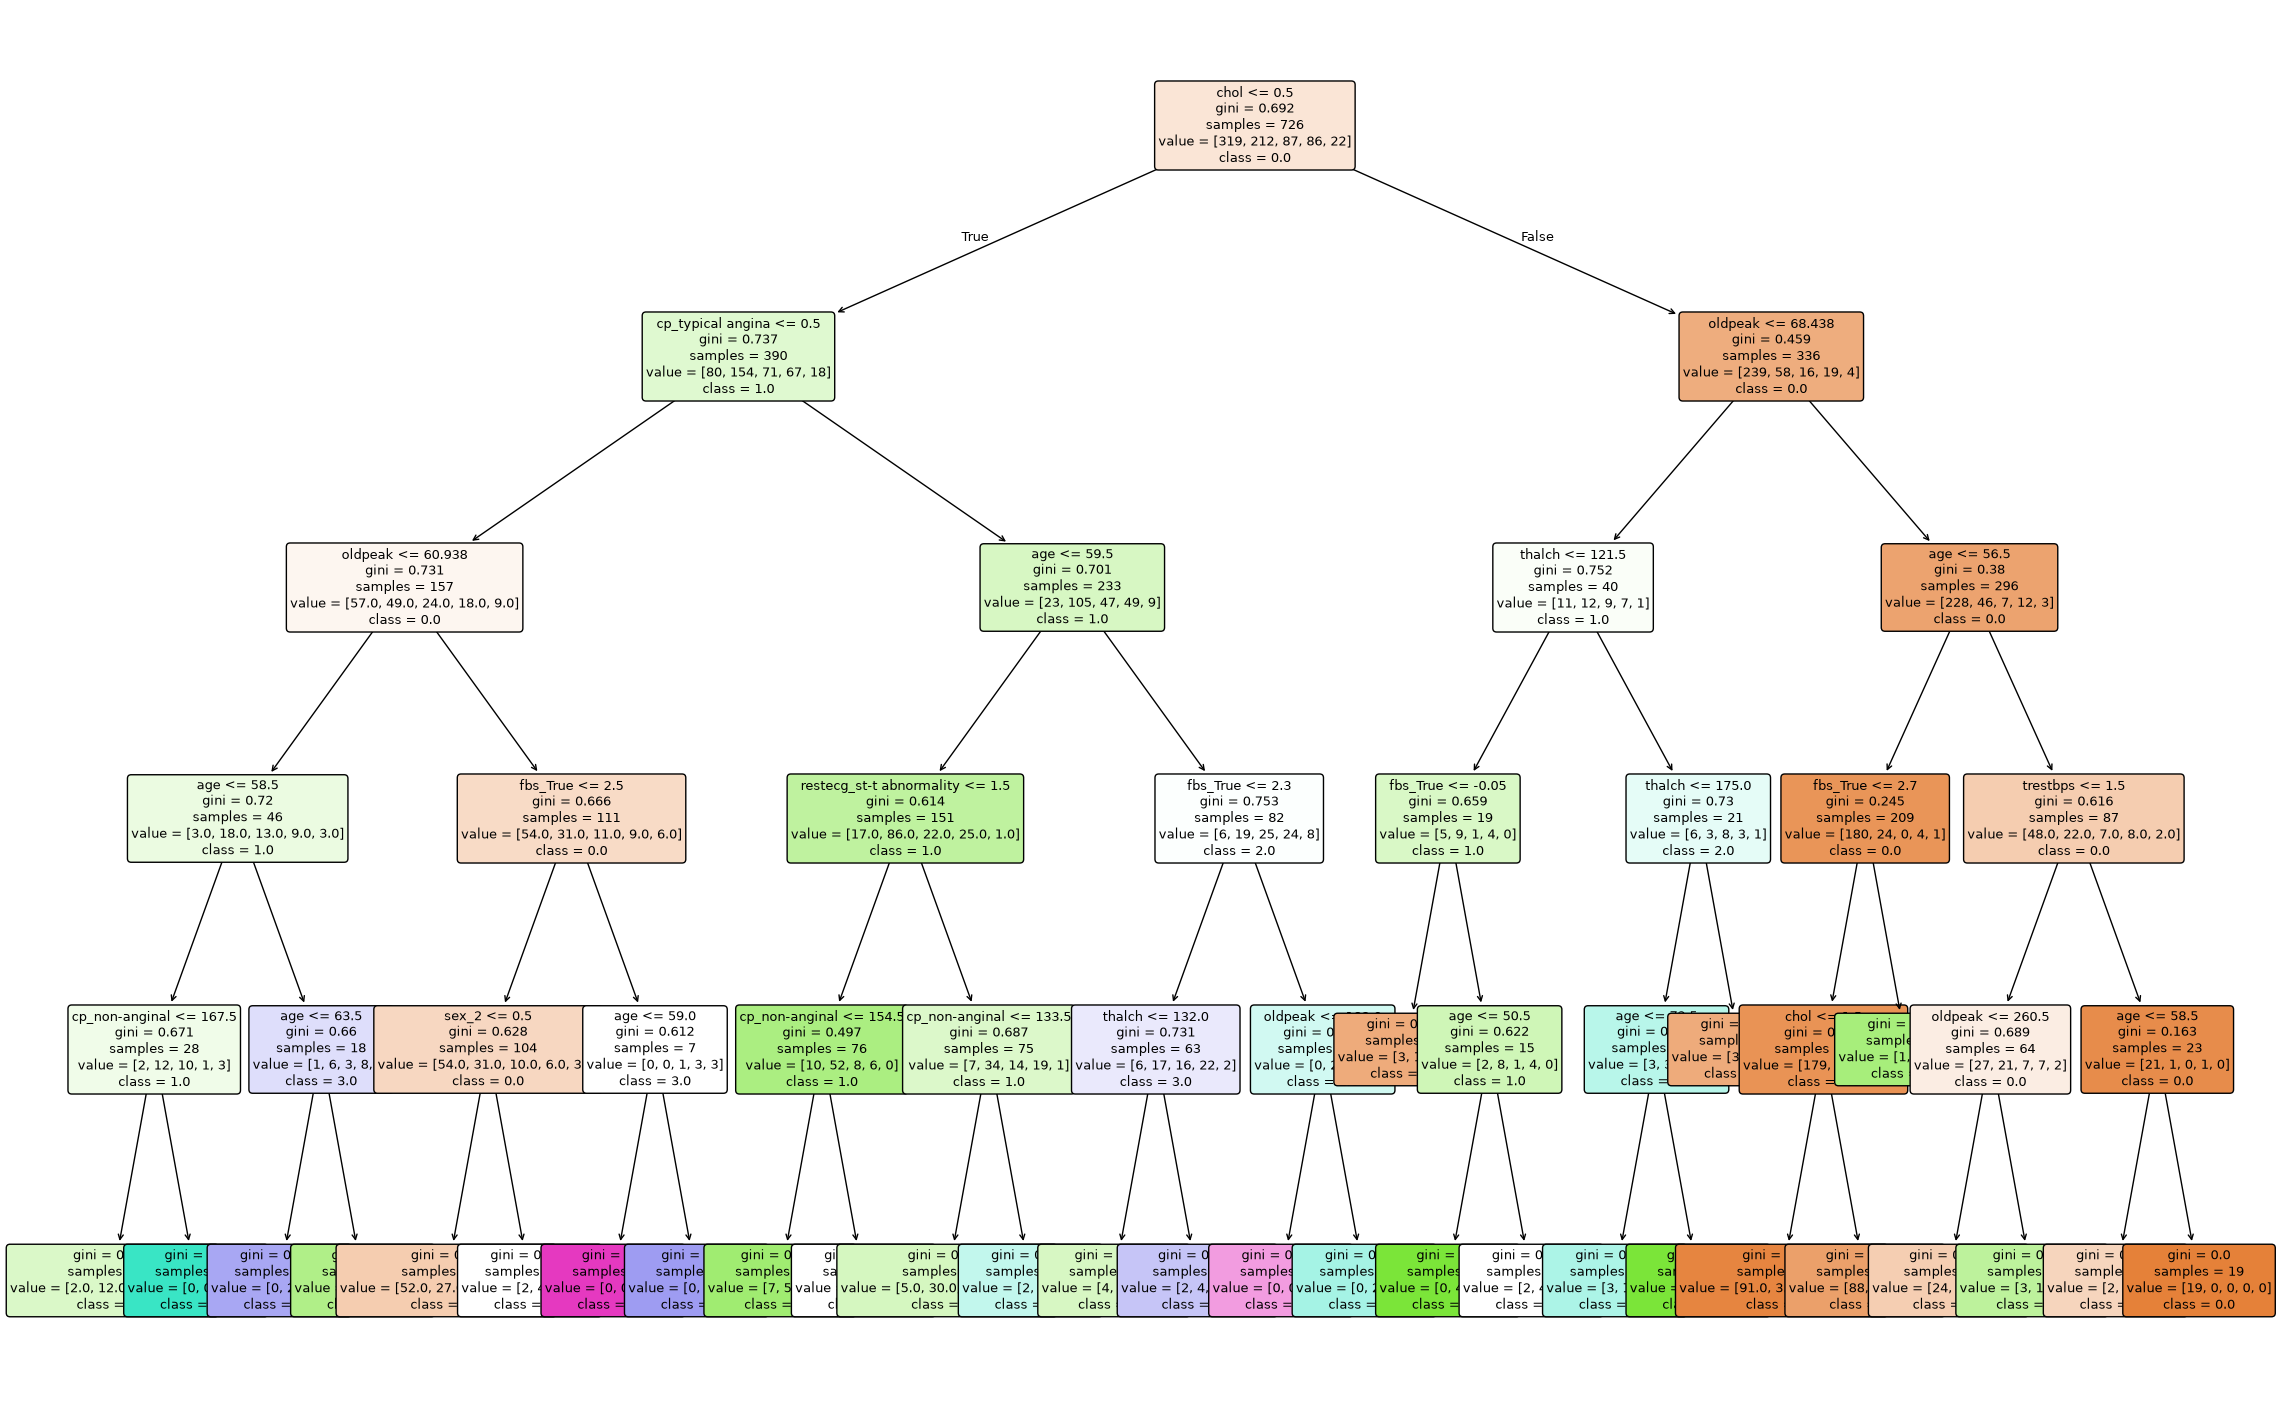

In [52]:
plt.figure(figsize=(28, 18))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in dt_model.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

In [53]:
print(y_train.value_counts())
print(y_test.value_counts())

num
0.0    319
1.0    212
2.0     87
3.0     86
4.0     22
Name: count, dtype: int64
num
0.0    80
1.0    53
2.0    22
3.0    21
4.0     6
Name: count, dtype: int64


In [54]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': dt_model.feature_importances_
})

In [55]:
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

     Feature  Importance
2         cp    0.380792
0        age    0.165871
4       chol    0.149162
9    oldpeak    0.074669
8      exang    0.056758
7     thalch    0.051556
3   trestbps    0.046746
1        sex    0.034435
11      thal    0.020811
5        fbs    0.019199
6    restecg    0.000000
10     slope    0.000000


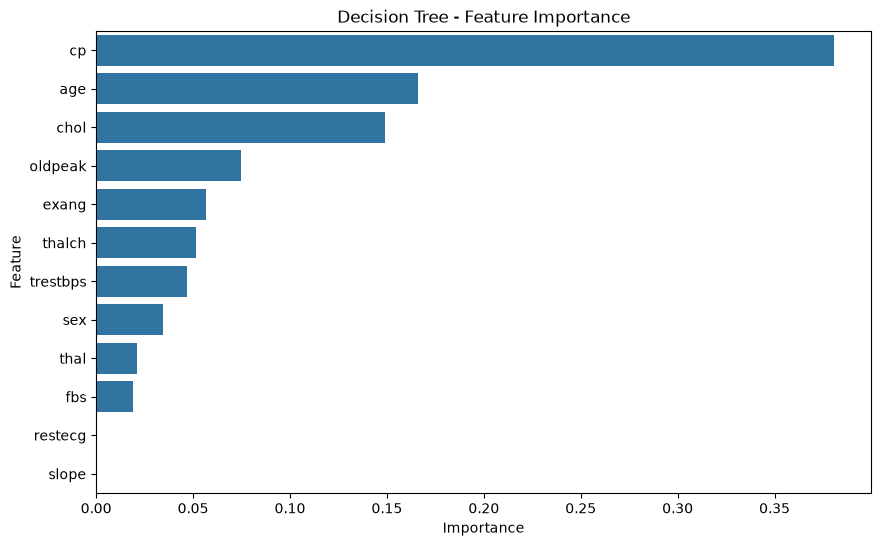

In [56]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Decision Tree - Feature Importance")
plt.show()

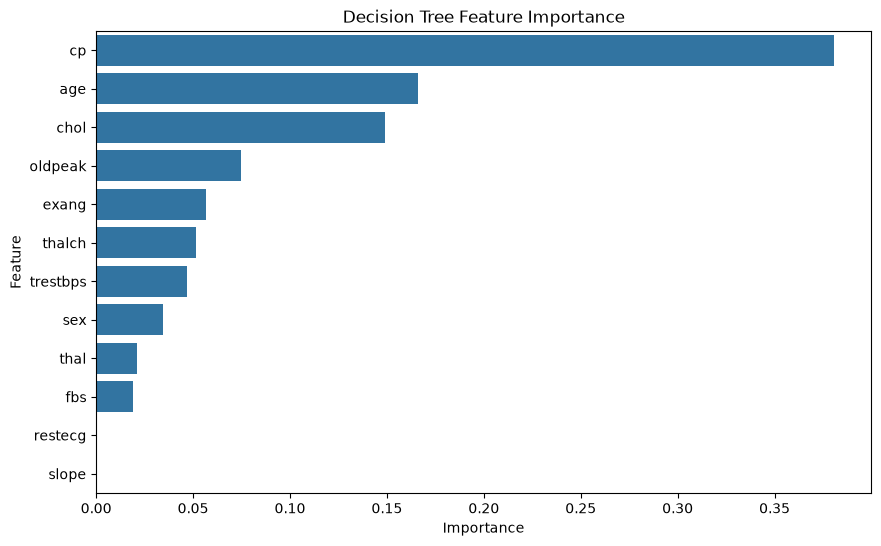

In [57]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Decision Tree Feature Importance')
plt.show()

## 11. Hyperparameter Tuning and Final Model Comparison

### 11.1 Hyperparameter Tuning
GridSearchCV is used to identify the best combination of Decision Tree hyperparameters.

The following parameters are explored:

- Maximum depth (`max_depth`)
- Minimum samples split (`min_samples_split`)
- Minimum samples leaf (`min_samples_leaf`)
- Splitting criterion (`criterion`)

### 11.2 Optimized Model
The best hyperparameters are used to create the optimized Decision Tree model.

### 11.3 Performance Comparison
The original and optimized models are compared using accuracy, precision, recall and F1 score.

### 11.4 Final Conclusion
The final model is evaluated to understand its predictive performance and identify areas for improvement.

In [58]:
from sklearn.metrics import accuracy_score

# Test different maximum depths
depth_values = [2, 3, 4, 5, 6, 8, 10]

depth_results = []

for depth in depth_values:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, predictions)
    
    depth_results.append({
        "max_depth": depth,
        "accuracy": accuracy
    })

depth_results_df = pd.DataFrame(depth_results)

depth_results_df

,max_depth,accuracy
0,2,0.538462
1,3,0.505495
2,4,0.516484
3,5,0.505495
4,6,0.500000
5,8,0.510989
6,10,0.456044


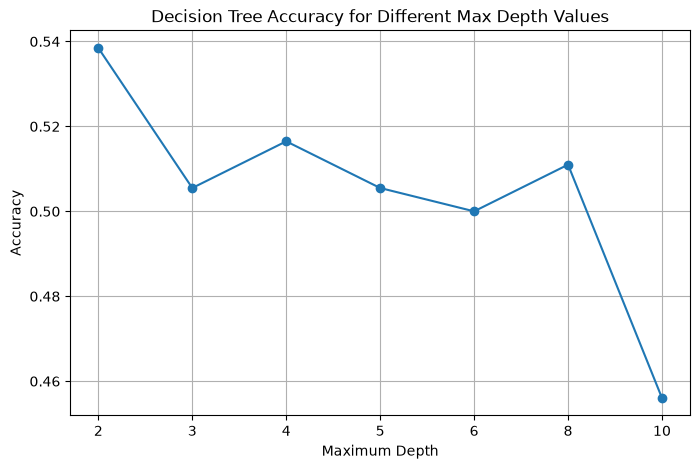

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_results_df["max_depth"].astype(str),
    depth_results_df["accuracy"],
    marker="o"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy for Different Max Depth Values")
plt.grid()
plt.show()

In [60]:
# Test different min_samples_split values
split_values = [2, 5, 10, 20, 30]

split_results = []

for split in split_values:
    model = DecisionTreeClassifier(
        min_samples_split=split,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, predictions)
    
    split_results.append({
        "min_samples_split": split,
        "accuracy": accuracy
    })

split_results_df = pd.DataFrame(split_results)

split_results_df

,min_samples_split,accuracy
0,2,0.445055
1,5,0.472527
2,10,0.472527
3,20,0.505495
4,30,0.516484


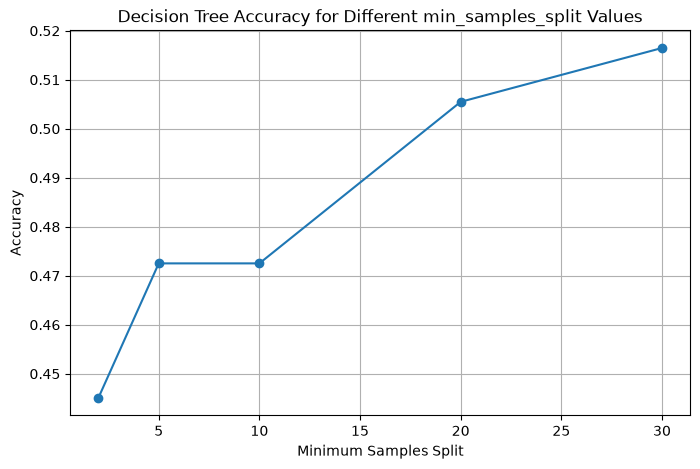

In [61]:
plt.figure(figsize=(8, 5))

plt.plot(
    split_results_df["min_samples_split"],
    split_results_df["accuracy"],
    marker="o"
)

plt.xlabel("Minimum Samples Split")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy for Different min_samples_split Values")
plt.grid()
plt.show()

In [62]:
# Test different criterion values
criterion_values = ["gini", "entropy"]

criterion_results = []

for criterion in criterion_values:
    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, predictions)
    
    criterion_results.append({
        "criterion": criterion,
        "accuracy": accuracy
    })

criterion_results_df = pd.DataFrame(criterion_results)

criterion_results_df

,criterion,accuracy
0,gini,0.445055
1,entropy,0.483516


In [63]:
# Get the best max_depth
best_depth = depth_results_df.loc[
    depth_results_df["accuracy"].idxmax(), "max_depth"
]

# Get the best min_samples_split
best_split = split_results_df.loc[
    split_results_df["accuracy"].idxmax(), "min_samples_split"
]

# Get the best criterion
best_criterion = criterion_results_df.loc[
    criterion_results_df["accuracy"].idxmax(), "criterion"
]

print("Best max_depth:", best_depth)
print("Best min_samples_split:", best_split)
print("Best criterion:", best_criterion)

Best max_depth: 2
Best min_samples_split: 30
Best criterion: entropy


In [64]:
# Create the tuned Decision Tree
tuned_dt = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_split=best_split,
    criterion=best_criterion,
    random_state=42
)

# Train the tuned model
tuned_dt.fit(X_train, y_train)

# Make predictions
tuned_pred = tuned_dt.predict(X_test)

print("Tuned Decision Tree Accuracy:",
      accuracy_score(y_test, tuned_pred))

Tuned Decision Tree Accuracy: 0.5494505494505495


In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict classes
tuned_pred = tuned_dt.predict(X_test)

# Predict probabilities
tuned_prob = tuned_dt.predict_proba(X_test)

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(y_test, tuned_pred)

tuned_precision = precision_score(
    y_test,
    tuned_pred,
    average="weighted"
)

tuned_recall = recall_score(
    y_test,
    tuned_pred,
    average="weighted"
)

tuned_f1 = f1_score(
    y_test,
    tuned_pred,
    average="weighted"
)

tuned_roc_auc = roc_auc_score(
    y_test,
    tuned_prob,
    multi_class="ovr",
    average="weighted"
)

print("Accuracy :", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall   :", tuned_recall)
print("F1-Score :", tuned_f1)
print("ROC-AUC  :", tuned_roc_auc)

Accuracy : 0.5494505494505495
Precision: 0.4446458303601161
Recall   : 0.5494505494505495
F1-Score : 0.47767732549640146
ROC-AUC  : 0.7265595806615832


c:\Users\saniy\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [69]:
print("y_test unique values:", y_test.unique())
print("Model classes:", tuned_dt.classes_)
print("Prediction shape:", tuned_prob.shape)

y_test unique values: [0. 2. 1. 4. 3.]
Model classes: [0. 1. 2. 3. 4.]
Prediction shape: (182,)


In [75]:
print("Classification Report:")
print(classification_report(y_test, tuned_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.40      0.41        80
           1       0.54      0.56      0.55       102

    accuracy                           0.49       182
   macro avg       0.48      0.48      0.48       182
weighted avg       0.49      0.49      0.49       182



##Key findings 
- Original model accuracy	50.55%
- Original precision (weighted)	47.11%
- Original recall (weighted)	50.55%
- Original F1-score (weighted)	48.54%
- Tuned model reported accuracy	54.95%

## 12. Conclusion

In this project, a Decision Tree Classification model was developed to predict the presence of heart disease using patient health attributes.

The dataset underwent exploratory data analysis, including checking missing values, identifying and treating outliers, analyzing feature distributions, and studying correlations between variables.

Categorical variables were encoded into numerical values, and the dataset was divided into training and testing sets to build and evaluate the model.

The feature importance analysis indicated that chest pain type (`cp`), age, and cholesterol (`chol`) were among the most influential features in the initial model.

The initial Decision Tree achieved an accuracy of approximately 50.55%. Hyperparameter tuning was performed to improve the model by experimenting with maximum depth, minimum samples split, and splitting criteria.

The results indicate that Decision Tree classification has potential for identifying patterns associated with heart disease. However, the model's predictive performance needs further improvement before it can be considered reliable.


In [79]:
print(y_train.unique())
print(y_test.unique())
print(dt_model.classes_)
print(tuned_dt.classes_)

[1 0]
[0 1]
[0. 1. 2. 3. 4.]
[0. 1. 2. 3. 4.]
